# ML Assignment 3 – Classification

## Objective
To apply supervised learning techniques to the breast cancer dataset available in the Scikit-learn library and compare the performance of five classification algorithms.

## Dataset
Breast Cancer Wisconsin Dataset from Scikit-learn.


In [1]:

# Import the required libraries
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Load the breast cancer dataset
cancer = load_breast_cancer()

# Separate features and target
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target, name="target")

# Display the first five rows
print("First five rows of the dataset:")
display(X.head())

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(pd.Series(y).value_counts().sort_index())

print("\nClass names:")
print(cancer.target_names)


First five rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Dataset shape: (569, 30)
Target shape: (569,)

Target classes:
target
0    212
1    357
Name: count, dtype: int64

Class names:
['malignant' 'benign']


In [2]:

# missing & duplicate values
print("Missing values in the dataset:")
print(X.isnull().sum().sum())

print("\nNumber of duplicate rows:", X.duplicated().sum())
print("\nData types:")
print(X.dtypes.value_counts())


Missing values in the dataset:
0

Number of duplicate rows: 0

Data types:
float64    30
Name: count, dtype: int64


In [4]:

# Split the original data before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit the imputer only on training data
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Fit the scaler only on training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("Missing values after imputation:",
      np.isnan(X_train_imputed).sum() +
      np.isnan(X_test_imputed).sum())

print("Training scaled mean:",
      round(X_train_scaled.mean(), 4))

print("Training scaled standard deviation:",
      round(X_train_scaled.std(), 4))


Training set shape: (455, 30)
Testing set shape: (114, 30)
Missing values after imputation: 0
Training scaled mean: -0.0
Training scaled standard deviation: 1.0


## Classification Algorithm Implementation

Five supervised classification algorithms are implemented: Logistic Regression, Decision Tree, Random Forest, Support Vector Machine (SVM), and k-Nearest Neighbors (k-NN). Their performance will be evaluated using the same training and testing sets.

In [5]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Define the five classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=10000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(),
    "k-NN": KNeighborsClassifier()
}

# Train and evaluate each model
results = []

for name, model in models.items():


    if name in ["Logistic Regression", "SVM", "k-NN"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train_imputed, y_train)
        y_pred = model.predict(X_test_imputed)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

# Display the comparison table
results_df = pd.DataFrame(results)
display(results_df.round(4))


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861
1,Decision Tree,0.9123,0.9559,0.9028,0.9286
2,Random Forest,0.9561,0.9589,0.9722,0.9655
3,SVM,0.9825,0.9861,0.9861,0.9861
4,k-NN,0.9561,0.9589,0.9722,0.9655


## Model Comparison

The performance of the five classification algorithms was evaluated using accuracy, precision, recall, and F1-score.

Logistic Regression and Support Vector Machine (SVM) achieved the best results, with an accuracy of 98.25% and an F1-score of 98.61%. Both models performed consistently well across the evaluation metrics.

Random Forest and k-Nearest Neighbors (k-NN) achieved an accuracy of 95.61% and an F1-score of 96.55%, indicating good classification performance.

The Decision Tree classifier performed the worst among the five models, achieving an accuracy of 91.23% and an F1-score of 92.86%.

Based on the test results, Logistic Regression and SVM are the best-performing models for this dataset, while Decision Tree is the lowest-performing model in this comparison.


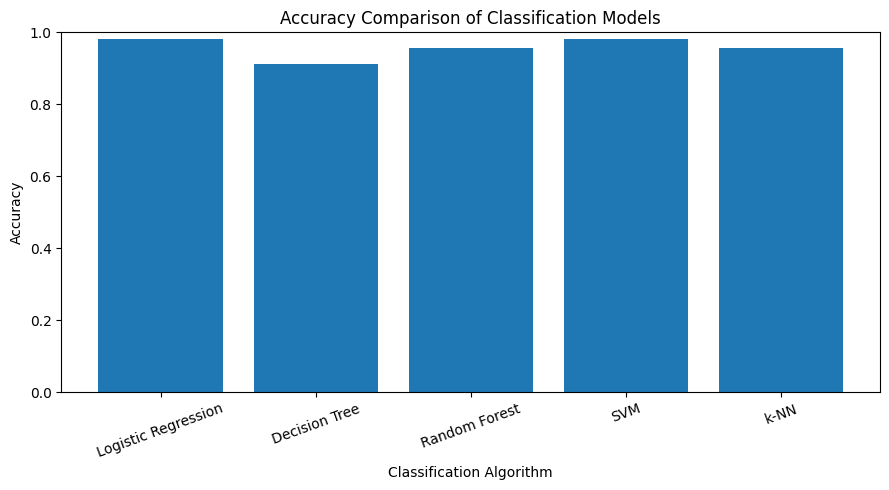

In [6]:
#adding a bar chart just for better visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy"]
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Conclusion

The breast cancer dataset was classified using Logistic Regression, Decision Tree, Random Forest, Support Vector Machine, and k-Nearest Neighbors.

Among the five algorithms, Logistic Regression and SVM achieved the highest accuracy of 98.25%, while Decision Tree achieved the lowest accuracy of 91.23%. The results demonstrate that different classification algorithms can produce different levels of performance on the same dataset.

Based on the evaluation metrics, Logistic Regression and SVM were the best-performing models in this experiment.
